In [1]:
from tld import get_fld
from urllib.parse import urlparse
import json
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
hars = {}
for crawl in ["desktop", "mobile", "block", "ignore"]:
    ordner = Path("../crawl_data_" + crawl)
    hars[crawl] = {}
    for har_path in ordner.glob("*.har"):
        domain = har_path.stem
        with open(har_path, encoding="utf-8") as har_file:
            har = json.load(har_file)
        hars[crawl][domain] = har

Get all the entries that were not blocked

In [3]:
def get_valid_entries(har):
    valid = []
    for entry in har['log']['entries']:
        if entry['response']['status'] <= 0:
            continue
        if entry['response'].get('_failureText'):
            continue
        valid.append(entry)
    return valid

Get the number of valid entries

In [4]:
def get_number_of_valid_entries(valid_entries):
    return len(valid_entries)

Get the number of third party requests per website

In [5]:
def is_third_party(page_url, request_url):
    request_domain = get_fld(request_url, fail_silently=True)
    if request_domain is None:
        return False
    return get_fld(page_url) != request_domain

def getNumThirdPartyRequests(entries, page_url):
    count = 0
    for entry in entries:
        req_url = entry['request']['url']
        if is_third_party(page_url, req_url):
            count += 1
    return count

Get the number of third-party domains per website

In [6]:
def get_third_party_domains(entries, page_url):
    tp_domains = set()
    for entry in entries:
        req_url = entry['request']['url']
        if is_third_party(page_url, req_url):
            tp_domains.add(get_fld(req_url))
    return tp_domains

def number_of_distinct_third_party_domains(domains):
    return len(domains)

Number of distinct third-party entities per website

In [7]:
entities = json.loads(open("disconnect/entities.json").read())
domain_to_entity = {}
for entity_name, entity_info in entities["entities"].items():
    for domain in entity_info["properties"] + entity_info["resources"]:
        domain_to_entity[domain] = entity_name


def get_third_party_entities(domains, map):
    thirdPartyEntities = set()
    for domain in domains:
        if (domain in map):
            thirdPartyEntities.add(map[domain])
    return thirdPartyEntities

def get_number_of_distict_third_party_entities_per_website(third_party_entities):
    return len(third_party_entities)

Find out if websites sends at least one request to an advertisement domain

In [8]:
services_file = open("disconnect/services.json", encoding="utf-8")
services = json.load(services_file)
services_file.close()

domain_to_categories = {}
for category, entity_list in services["categories"].items():
    for entity_dict in entity_list:
        for entity_name, entity_info in entity_dict.items():
            for key,value in entity_info.items():
                if isinstance(value, list):
                    for domain in value:
                        domain_to_categories.setdefault(domain, set()).add(category)

def has_website_send_request(valid_entries, category):
    for entry in valid_entries:
        request_url = entry["request"]["url"]
        request_domain = get_fld(request_url, fail_silently=True)
        if request_domain is None:
            continue
        if category in domain_to_categories.get(request_domain,set()) :
            return True
    return False


Get the country of the Website

In [ ]:
sites = pd.read_csv("../sites.csv")
domain_to_country = {}
for domain, country in zip(sites["domain"], sites["country"]):
    domain_to_country[domain] = country


Prepare data for plotting 

In [ ]:
# Final page URL after redirects: first main document response that is not a redirect (3xx)
def get_page_url(har):
    for entry in har['log']['entries']:
        status = entry['response']['status']
        if entry.get('_resourceType') == 'document' and status > 0 and not (300 <= status < 400):
            return entry['request']['url']
    return None

rows = []
for crawl in hars:
    for site in hars[crawl]:
        har = hars[crawl][site]
        page_url = get_page_url(har)
        valid_entries = get_valid_entries(har)
        third_party_domains = get_third_party_domains(valid_entries, page_url)
        third_party_entities = get_third_party_entities(third_party_domains, domain_to_entity)

        rows.append({
            "site": site,
            "mode": crawl,
            "num_requests": get_number_of_valid_entries(valid_entries),
            "num_third_party_requests": getNumThirdPartyRequests(valid_entries, page_url),
            "num_dist_third_party_domains": number_of_distinct_third_party_domains(third_party_domains),
            "num_dist_third_party_entites_per_website": get_number_of_distict_third_party_entities_per_website(third_party_entities),
            "contacts_advertising": has_website_send_request(valid_entries, "Advertising"),
            "contacts_analytics":   has_website_send_request(valid_entries, "Analytics"),
            "country": domain_to_country[site]
        })

df = pd.DataFrame(rows)
df

,site,mode,num_requests,num_third_party_requests,num_dist_third_party_domains,num_dist_third_party_entites_per_website,contacts_advertising,contacts_analytics
0,yale.edu,desktop,72,29,8,3,False,True
1,glasgow.ac.uk,desktop,158,103,21,6,True,True
2,eur.nl,desktop,63,13,7,4,True,False
3,utwente.nl,desktop,67,33,4,1,False,True
4,ru.nl,desktop,71,40,19,8,True,True
...,...,...,...,...,...,...,...,...
115,nottingham.ac.uk,ignore,70,29,6,4,True,False
116,harvard.edu,ignore,77,23,10,4,True,True
117,vu.nl,ignore,45,21,1,0,False,False
118,mit.edu,ignore,28,8,2,0,False,False


Plots for 1a - 1d

In [ ]:
sns.boxplot(df, x="mode", y="num_requests")
plt.xlabel("Crawl")
plt.ylabel("Number of requests per website")
plt.show()

In [ ]:
sns.boxplot(df, x="mode", y="num_third_party_requests")
plt.xlabel("Crawl")
plt.ylabel("Number of third-party requests per website")
plt.show()

In [ ]:
sns.boxplot(df, x="mode", y="num_dist_third_party_domains")
plt.xlabel("Crawl")
plt.ylabel("Number of distinct third-party domains per website")
plt.show()

In [ ]:
sns.boxplot(df, x="mode", y="num_dist_third_party_entites_per_website")
plt.xlabel("Crawl")
plt.ylabel("Number of distinct third-party entities p.w., using Disconnect")
plt.show()

Create Table to compare data from 1a - 1d

In [10]:
metrics = ["num_requests", "num_third_party_requests", "num_dist_third_party_domains", "num_dist_third_party_entites_per_website"]
table = df.groupby("mode")[metrics].agg(["min", "median", "max"]).T.unstack()
table

mode                                     block               desktop         \
                                           min median    max     min median   
num_requests                              28.0   66.0  235.0    28.0  101.0   
num_third_party_requests                   2.0   22.0  116.0     8.0   54.5   
num_dist_third_party_domains               1.0    5.0   13.0     2.0   14.5   
num_dist_third_party_entites_per_website   0.0    1.0    4.0     0.0    4.0   

mode                                            ignore               mobile  \
                                            max    min median    max    min   
num_requests                              272.0   28.0   62.0  133.0   27.0   
num_third_party_requests                  201.0    5.0   21.5   90.0    7.0   
num_dist_third_party_domains               36.0    1.0    6.0   15.0    1.0   
num_dist_third_party_entites_per_website   21.0    0.0    2.0    5.0    0.0   

mode                                                    
                                         median    max  
num_requests                               90.5  265.0  
num_third_party_requests                   53.5  195.0  
num_dist_third_party_domains               14.5   36.0  
num_dist_third_party_entites_per_website    4.0   21.0

Barplot for 3 a,b

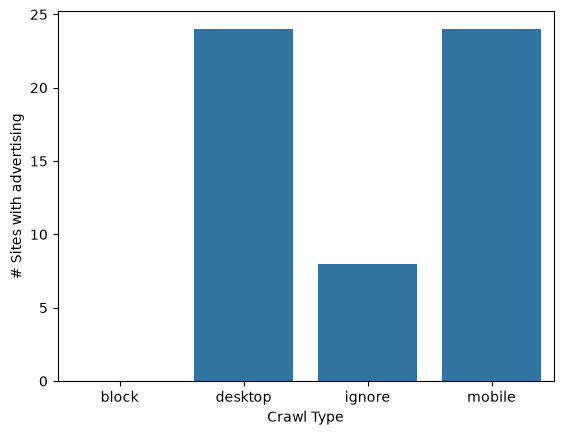

In [13]:
advertising_counts = df.groupby("mode")["contacts_advertising"].sum().reset_index()
sns.barplot(advertising_counts, x="mode", y="contacts_advertising")
plt.xlabel("Crawl Type")
plt.ylabel("# Sites with advertising")
plt.show()

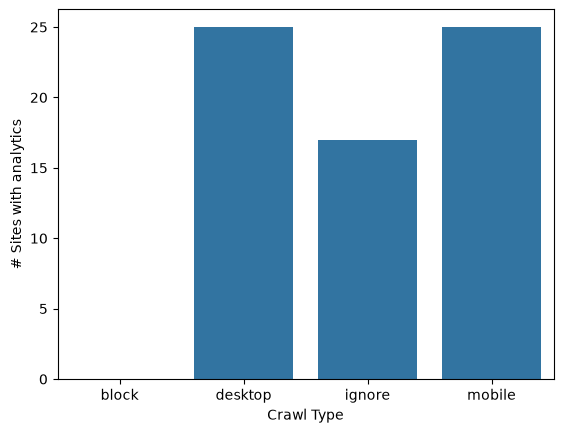

In [14]:
analytics_counts = df.groupby("mode")["contacts_analytics"].sum().reset_index()
sns.barplot(analytics_counts, x="mode", y="contacts_analytics")
plt.xlabel("Crawl Type")
plt.ylabel("# Sites with analytics")
plt.show()

Analysis for 4

In [ ]:
country_table = df[df["mode"]=="desktop"].groupby("country")[metrics].agg(["min", "median", "max"]).T.unstack()
country_table